# 03 · Detección de emociones en tiempo real

**Proyecto:** Emotion Detection Assistant · **Autor:** Edwar Trujillo · **Materia:** Inteligencia Artificial (FUP)

Este notebook corresponde a la **Fase 3**: tomar el modelo elegido en la Fase 2 (`improved_model_v2.keras` + TTA) y usarlo con la webcam para detectar rostros y clasificar su emoción en tiempo real.

| Parte | Contenido | Estado |
|---|---|---|
| 1 | Verificación del modelo en el entorno local | ✅ hecha |
| 2 | Detección de rostros con Haar Cascade | ✅ este notebook |
| 3 | Predicción en vivo con la webcam (TTA) | pendiente |
| 4 | Suavizado temporal e historial de emociones | pendiente |

**Privacidad:** no se guarda video ni imágenes de la webcam; solo etiquetas de emoción en memoria.

## Parte 1 · Verificación del modelo en el entorno local

**¿Por qué hace falta?** El modelo se entrenó y se guardó en **Google Colab con Keras 3.13.2**, pero el entorno local `emotion-ai` tiene **Keras 3.15.1**. El formato `.keras` es un archivo zip que guarda:

- `config.json`: la **arquitectura** (qué capas hay y cómo se conectan),
- `model.weights.h5`: los **pesos** aprendidos,
- `metadata.json`: la versión de Keras con la que se guardó.

Keras promete compatibilidad hacia adelante dentro de la versión 3 (un archivo de 3.13 debe abrir en 3.15), pero hay que **comprobarlo**, porque si una capa cambiara su configuración entre versiones, el modelo podría no cargar o, peor, cargar y predecir mal sin dar error.

**Cómo lo verificamos** (de lo más simple a lo más exigente):
1. Que el archivo **cargue** sin errores.
2. Que la **forma** de entrada y salida sea la esperada: `(48, 48, 1)` → 7 probabilidades.
3. Que incluya la capa **`Rescaling(1/255)`**, porque en tiempo real le pasaremos los píxeles en 0-255.
4. La prueba definitiva: volver a evaluar el **conjunto de test** y obtener el mismo **66,54 %** de la Fase 2. Si los pesos se hubieran cargado mal, el resultado caería mucho.

In [13]:
# --- Librerías ---
import json                 # leer los archivos de configuración (.json)
import time                 # medir el tiempo de inferencia
from pathlib import Path    # manejar rutas de archivos de forma segura en Windows

import cv2                  # OpenCV: leer imágenes, webcam y detección de rostros
import numpy as np          # operaciones con matrices (las imágenes son matrices)
import tensorflow as tf
import keras

# Versiones del entorno: dejarlas impresas sirve como evidencia para el reporte
print(f"TensorFlow: {tf.__version__}")
print(f"Keras:      {keras.__version__}")
print(f"OpenCV:     {cv2.__version__}")
print(f"NumPy:      {np.__version__}")

TensorFlow: 2.21.0
Keras:      3.15.1
OpenCV:     4.14.0
NumPy:      2.4.6


In [14]:
# --- Rutas del proyecto ---
# El notebook vive en notebooks/, así que la raíz del proyecto es la carpeta padre.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODELS_DIR = PROJECT_ROOT / "models"
TEST_DIR = PROJECT_ROOT / "data" / "fer2013" / "test"
METRICS_DIR = PROJECT_ROOT / "reports" / "metrics"

print("Raíz del proyecto:", PROJECT_ROOT)
for path in (MODELS_DIR, TEST_DIR, METRICS_DIR):
    print(f"  {'OK ' if path.exists() else 'NO EXISTE'}  {path}")

Raíz del proyecto: C:\Users\Personal\Projects\emotion-detection-assistant
  OK   C:\Users\Personal\Projects\emotion-detection-assistant\models
  OK   C:\Users\Personal\Projects\emotion-detection-assistant\data\fer2013\test
  OK   C:\Users\Personal\Projects\emotion-detection-assistant\reports\metrics


In [15]:
# --- Configuración del modelo elegido en la Fase 2 ---
# class_names.json: orden de las clases tal como salen de la capa softmax (índice 0 = angry, ...)
with open(MODELS_DIR / "class_names.json", encoding="utf-8") as f:
    CLASS_NAMES = json.load(f)

# selected_model.json: qué archivo usar y si se aplica TTA (decisión ADR-007)
with open(MODELS_DIR / "selected_model.json", encoding="utf-8") as f:
    SELECTED = json.load(f)

MODEL_PATH = MODELS_DIR / SELECTED["model_file"]
USE_TTA = SELECTED["use_tta"]

print("Clases:", CLASS_NAMES)
print("Modelo:", MODEL_PATH.name, f"({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print("TTA:   ", USE_TTA)

Clases: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Modelo: improved_model_v2.keras (23.6 MB)
TTA:    True


### 1.1 Cargar el modelo

Usamos `compile=False` porque aquí **solo vamos a predecir**: no necesitamos el optimizador (Adam), la función de pérdida ni las métricas, que solo sirven para entrenar. Así la carga es más rápida y evitamos posibles incompatibilidades del optimizador entre versiones.

Si el modelo tiene capas de *data augmentation* (`RandomFlip`, `RandomRotation`...), no hay problema: Keras las **desactiva automáticamente al predecir** (solo actúan con `training=True`).

In [16]:
# --- Cargar el modelo (si hay un problema de versiones, aparecería aquí como error o warning) ---
import warnings

with warnings.catch_warnings(record=True) as load_warnings:
    warnings.simplefilter("always")
    model = keras.models.load_model(MODEL_PATH, compile=False)

print(f"Modelo cargado: {model.name}")
print(f"Parámetros:     {model.count_params():,}")
print(f"Entrada:        {model.input_shape}   (lote, alto, ancho, canales)")
print(f"Salida:         {model.output_shape}  (lote, 7 probabilidades)")
print(f"Warnings al cargar: {len(load_warnings)}")
for w in load_warnings:
    print("   -", str(w.message)[:200])

Modelo cargado: improved_model
Parámetros:     5,872,455
Entrada:        (None, 48, 48, 1)   (lote, alto, ancho, canales)
Salida:         (None, 7)  (lote, 7 probabilidades)
Warnings al cargar: 0


In [17]:
# --- Versión de Keras con la que se guardó el archivo ---
# El .keras es un zip; metadata.json indica la versión usada en Colab.
import zipfile

with zipfile.ZipFile(MODEL_PATH) as zf:
    metadata = json.loads(zf.read("metadata.json"))
print(f"Guardado con Keras {metadata.get('keras_version')}  →  cargado con Keras {keras.__version__}")

Guardado con Keras 3.13.2  →  cargado con Keras 3.15.1


In [18]:
# --- Comprobaciones de estructura ---
layer_types = [type(layer).__name__ for layer in model.layers]

checks = {
    "Entrada 48x48x1 (grises)": tuple(model.input_shape[1:]) == (48, 48, 1),
    "Salida de 7 clases": model.output_shape[-1] == len(CLASS_NAMES) == 7,
    "Incluye Rescaling (entrada 0-255)": "Rescaling" in layer_types,
    "Última activación softmax": model.layers[-1].get_config().get("activation") == "softmax",
}
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")

# Prueba rápida: con una imagen gris (todos los píxeles = 128) las probabilidades deben sumar 1
dummy = np.full((1, 48, 48, 1), 128, dtype=np.float32)
probs = model.predict(dummy, verbose=0)[0]
print(f"\nSuma de probabilidades: {probs.sum():.4f} (debe ser 1.0000)")

✅ Entrada 48x48x1 (grises)
✅ Salida de 7 clases
✅ Incluye Rescaling (entrada 0-255)
✅ Última activación softmax

Suma de probabilidades: 1.0000 (debe ser 1.0000)


### 1.2 Función de predicción con TTA

**TTA (Test-Time Augmentation):** en lugar de predecir una sola vez, predecimos el rostro **y su espejo horizontal** y promediamos las dos distribuciones de probabilidad. Una cara sonriente sigue siendo sonriente al voltearla, así que el espejo da una "segunda opinión" del mismo modelo; al promediar, los errores aleatorios de cada predicción se compensan parcialmente. En validación subió la accuracy de 66,27 % a 66,98 %, y por eso se eligió (ADR-007).

El costo es que cada rostro se procesa **dos veces**. Para no hacer dos llamadas al modelo, juntamos las imágenes originales y las volteadas en **un solo lote**, que es más eficiente.

Esta misma función se usará en tiempo real (Parte 3), así que el preprocesamiento de la verificación es **el mismo** que tendrá la webcam: imagen en grises de OpenCV, 48x48, valores 0-255 sin normalizar (la normalización la hace la capa `Rescaling` dentro del modelo).

In [19]:
def predict_emotions(faces: np.ndarray, use_tta: bool = USE_TTA) -> np.ndarray:
    # Predice las probabilidades de las 7 emociones.
    #
    # faces: arreglo (N, 48, 48) o (N, 48, 48, 1) con rostros en grises, valores 0-255.
    # Devuelve: arreglo (N, 7) con probabilidades (cada fila suma 1).
    x = np.asarray(faces, dtype=np.float32)
    if x.ndim == 3:                       # (N, 48, 48) -> (N, 48, 48, 1): el modelo espera un canal
        x = x[..., np.newaxis]
    if not use_tta:
        return model.predict(x, verbose=0)

    flipped = x[:, :, ::-1, :]            # espejo horizontal: invierte el eje del ancho
    batch = np.concatenate([x, flipped])  # un solo lote con originales + espejos
    probs = model.predict(batch, verbose=0)
    n = len(x)
    return (probs[:n] + probs[n:]) / 2    # promedio de las dos predicciones


# Prueba de la función con la imagen gris
print(predict_emotions(dummy[..., 0]).round(3))

[[0.031 0.    0.145 0.008 0.317 0.498 0.   ]]


### 1.3 Prueba definitiva: reevaluar el conjunto de test

Cargamos las 7.178 imágenes de `data/fer2013/test` con **OpenCV** (como en tiempo real), predecimos con TTA y comparamos con la accuracy de la Fase 2 (**66,54 %**). Admitimos una diferencia de hasta **0,5 puntos**, porque OpenCV y TensorFlow decodifican los JPEG con librerías distintas y pueden variar algún píxel por redondeo. Si la diferencia fuera grande, significaría que los pesos o el preprocesamiento no coinciden.

También medimos el **tiempo de inferencia por rostro**, que nos dice cuántos FPS podemos esperar en tiempo real con la CPU.

In [20]:
# --- Cargar el test con OpenCV ---
images, labels = [], []
for class_index, class_name in enumerate(CLASS_NAMES):
    for img_path in sorted((TEST_DIR / class_name).glob("*.jpg")):
        img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)  # matriz 48x48, valores 0-255
        if img is None:
            continue
        if img.shape != (48, 48):                               # seguridad: todas deberían ser 48x48
            img = cv2.resize(img, (48, 48), interpolation=cv2.INTER_AREA)
        images.append(img)
        labels.append(class_index)

X_test = np.stack(images)
y_test = np.array(labels)
print(f"Imágenes de test: {len(X_test):,}  | forma: {X_test.shape}  | rango: {X_test.min()}-{X_test.max()}")

Imágenes de test: 7,178  | forma: (7178, 48, 48)  | rango: 0-255


In [21]:
# --- Predecir por lotes y medir tiempo ---
BATCH_SIZE = 256
start = time.perf_counter()
probs_test = np.concatenate([
    predict_emotions(X_test[i:i + BATCH_SIZE]) for i in range(0, len(X_test), BATCH_SIZE)
])
elapsed = time.perf_counter() - start

y_pred = probs_test.argmax(axis=1)                        # clase con mayor probabilidad (top-1)
top2 = np.argsort(probs_test, axis=1)[:, -2:]             # las 2 clases más probables
accuracy = (y_pred == y_test).mean()
top2_accuracy = (top2 == y_test[:, None]).any(axis=1).mean()

print(f"Accuracy top-1: {accuracy:.2%}")
print(f"Accuracy top-2: {top2_accuracy:.2%}")
print(f"Tiempo total: {elapsed:.1f} s  →  {1000 * elapsed / len(X_test):.2f} ms por rostro (con TTA, en lotes)")

Accuracy top-1: 66.54%
Accuracy top-2: 83.63%
Tiempo total: 102.1 s  →  14.23 ms por rostro (con TTA, en lotes)


In [22]:
# --- Comparación con la Fase 2 ---
REFERENCE_ACCURACY = 0.6654   # v2 + TTA en test (reports/metrics/model_comparison.csv)
REFERENCE_TOP2 = 0.8363
TOLERANCE = 0.005             # 0,5 puntos porcentuales

diff = abs(accuracy - REFERENCE_ACCURACY)
print(f"Fase 2 (Colab, Keras 3.13.2): {REFERENCE_ACCURACY:.2%}  | top-2 {REFERENCE_TOP2:.2%}")
print(f"Local  (Keras {keras.__version__}):        {accuracy:.2%}  | top-2 {top2_accuracy:.2%}")
print(f"Diferencia: {100 * diff:.2f} puntos")
if diff <= TOLERANCE:
    print("✅ El modelo carga y predice igual que en Colab: listo para tiempo real.")
else:
    print("⚠️ La diferencia supera 0,5 puntos: revisar el modelo o el preprocesamiento antes de seguir.")

Fase 2 (Colab, Keras 3.13.2): 66.54%  | top-2 83.63%
Local  (Keras 3.15.1):        66.54%  | top-2 83.63%
Diferencia: 0.00 puntos
✅ El modelo carga y predice igual que en Colab: listo para tiempo real.


In [23]:
# --- Guardar la evidencia de la verificación (para el reporte) ---
verification = {
    "model_file": MODEL_PATH.name,
    "saved_with_keras": metadata.get("keras_version"),
    "loaded_with_keras": keras.__version__,
    "tensorflow": tf.__version__,
    "load_warnings": len(load_warnings),
    "use_tta": USE_TTA,
    "test_images": int(len(X_test)),
    "test_accuracy": round(float(accuracy), 4),
    "test_top2_accuracy": round(float(top2_accuracy), 4),
    "reference_accuracy": REFERENCE_ACCURACY,
    "ms_per_face_batched": round(1000 * elapsed / len(X_test), 3),
}
METRICS_DIR.mkdir(parents=True, exist_ok=True)
with open(METRICS_DIR / "local_model_verification.json", "w", encoding="utf-8") as f:
    json.dump(verification, f, indent=2)
print(json.dumps(verification, indent=2))

{
  "model_file": "improved_model_v2.keras",
  "saved_with_keras": "3.13.2",
  "loaded_with_keras": "3.15.1",
  "tensorflow": "2.21.0",
  "load_warnings": 0,
  "use_tta": true,
  "test_images": 7178,
  "test_accuracy": 0.6654,
  "test_top2_accuracy": 0.8363,
  "reference_accuracy": 0.6654,
  "ms_per_face_batched": 14.226
}


### 1.4 Comprobación previa para la Parte 2: Haar Cascade

OpenCV 4.x trae incluidos los archivos XML del detector Viola-Jones (en OpenCV 5 se retiraron del paquete principal, por eso fijamos la versión 4.14). Verificamos que el de rostros frontales exista y cargue (si el archivo no se encuentra, `CascadeClassifier` no da error, solo queda "vacío", por eso usamos `.empty()`).

In [24]:
# OpenCV 5 sacó el CascadeClassifier del paquete principal; este proyecto usa OpenCV 4.x
print("OpenCV:", cv2.__version__)
if not hasattr(cv2, "CascadeClassifier"):
    print("❌ Esta versión de OpenCV no trae CascadeClassifier.")
    print("   Solución (Anaconda Prompt, con emotion-ai activado): pip install opencv-python==4.14.0.94")
else:
    CASCADE_PATH = Path(cv2.data.haarcascades) / "haarcascade_frontalface_default.xml"
    face_detector = cv2.CascadeClassifier(str(CASCADE_PATH))
    print("Archivo:", CASCADE_PATH)
    print("✅ Haar Cascade cargado" if not face_detector.empty() else "❌ No se pudo cargar el Haar Cascade")

OpenCV: 4.14.0
Archivo: C:\Users\Personal\anaconda3\envs\emotion-ai\Lib\site-packages\cv2\data\haarcascade_frontalface_default.xml
✅ Haar Cascade cargado


### Evidencias de la Parte 1 para el reporte
- Captura de la celda de **versiones** y de la de **"Guardado con Keras 3.13.2 → cargado con Keras 3.15.1"**.
- Captura de la **comparación con la Fase 2** (accuracy local vs. Colab).
- Archivo `reports/metrics/local_model_verification.json` (incluye los **ms por rostro**, útil para justificar los FPS en tiempo real).

## Parte 2 · Detección de rostros con Haar Cascade (Viola-Jones)

El modelo CNN **no busca caras**: solo clasifica una imagen de 48x48 que ya es un rostro. Por eso, antes de clasificar, hay que **encontrar dónde está cada cara** en el cuadro de la webcam. Para eso usamos el detector de **Viola-Jones (2001)**, que OpenCV implementa como *Haar Cascade*.

### ¿Cómo funciona Viola-Jones?
1. **Características tipo Haar:** son rectángulos blancos y negros que miden diferencias de brillo entre zonas vecinas. Ejemplo: la zona de los ojos suele ser **más oscura** que la de las mejillas, y el puente de la nariz **más claro** que los ojos. Cada característica es un número: suma de píxeles del rectángulo blanco menos la del negro.
2. **Imagen integral:** una tabla precalculada donde cada posición guarda la suma de todos los píxeles de arriba a la izquierda. Con ella, la suma de **cualquier rectángulo** se obtiene con solo 4 operaciones, sin importar su tamaño. Esto hace al detector muy rápido.
3. **AdaBoost:** de cientos de miles de características posibles, el entrenamiento escoge las pocas que mejor separan "cara" de "no cara" y las combina en clasificadores.
4. **Cascada:** los clasificadores se ordenan en etapas, de los más simples a los más exigentes. Una ventana que falla una etapa se **descarta de inmediato**. Como la mayoría de la imagen no es cara, casi todo se descarta en las primeras etapas y solo las zonas prometedoras llegan al final.

El detector recorre la imagen con una **ventana deslizante** a varios tamaños (escalas), porque las caras pueden estar cerca o lejos de la cámara.

### Parámetros de `detectMultiScale`
| Parámetro | Qué controla | Efecto |
|---|---|---|
| `scaleFactor` | Cuánto se reduce la imagen entre una escala y la siguiente (1.1 = 10 %) | Menor (1.05): más escalas, detecta mejor pero es **más lento**. Mayor (1.3): más rápido pero puede saltarse caras |
| `minNeighbors` | Cuántas detecciones superpuestas necesita una zona para aceptarse como cara | Bajo (1-3): detecta más pero con **falsos positivos**. Alto (8+): más estricto, puede perder caras reales |
| `minSize` | Tamaño mínimo de cara en píxeles | Ignora caras pequeñas o lejanas y ahorra tiempo |

**Ecualización de histograma:** antes de detectar aplicamos `cv2.equalizeHist`, que reparte mejor los niveles de gris y ayuda cuando hay poca luz o contraluz. Se usa **solo para detectar**. El recorte que va al modelo sale de la imagen original, porque la CNN se entrenó con imágenes de FER-2013 sin ecualizar.

**Limitaciones (para el reporte):** el `frontalface_default` está entrenado con caras **de frente**. Falla con perfiles, rostros muy inclinados o tapados (manos, mascarilla) y con mala iluminación. Para eso existen detectores con redes neuronales (por ejemplo, el DNN de OpenCV), que son más precisos pero más pesados.

In [25]:
# --- Parámetros del detector (valores por defecto recomendados para webcam) ---
SCALE_FACTOR = 1.1        # reduce la imagen 10 % en cada escala
MIN_NEIGHBORS = 5         # pide 5 detecciones superpuestas para aceptar una cara
MIN_FACE_SIZE = (60, 60)  # ignora caras menores a 60x60 píxeles (muy lejanas)
FACE_SIZE = 48            # tamaño de entrada del modelo (FER-2013)

CASCADE_PATH = Path(cv2.data.haarcascades) / "haarcascade_frontalface_default.xml"
face_detector = cv2.CascadeClassifier(str(CASCADE_PATH))
assert not face_detector.empty(), "No se pudo cargar el Haar Cascade"


def detect_faces(gray, scale_factor=SCALE_FACTOR, min_neighbors=MIN_NEIGHBORS, min_size=MIN_FACE_SIZE):
    # Detecta rostros en una imagen en grises.
    # Devuelve una lista de cajas (x, y, ancho, alto), de la cara más grande a la más pequeña.
    equalized = cv2.equalizeHist(gray)                     # mejora el contraste solo para detectar
    boxes = face_detector.detectMultiScale(
        equalized,
        scaleFactor=scale_factor,
        minNeighbors=min_neighbors,
        minSize=min_size,
    )
    boxes = [tuple(int(v) for v in box) for box in boxes]  # numpy -> enteros de Python
    return sorted(boxes, key=lambda b: b[2] * b[3], reverse=True)


def extract_face(gray, box, size=FACE_SIZE):
    # Recorta el rostro de la imagen en grises ORIGINAL y lo lleva a 48x48 (valores 0-255).
    x, y, w, h = box
    face = gray[y:y + h, x:x + w]
    # INTER_AREA es el mejor método para reducir imágenes: promedia píxeles y evita "dientes de sierra"
    return cv2.resize(face, (size, size), interpolation=cv2.INTER_AREA)


print("Detector listo:", CASCADE_PATH.name)

Detector listo: haarcascade_frontalface_default.xml


### 2.1 Tomar una foto de prueba

Tomamos **un solo cuadro** de la webcam para probar el detector con calma, antes de pasar al video en vivo (Parte 3).

- `cv2.CAP_DSHOW` usa **DirectShow**, el sistema de video de Windows; con él la cámara suele abrir más rápido. Si falla, se intenta con el modo por defecto.
- Se descartan los primeros cuadros (*warm-up*) porque la cámara tarda un momento en ajustar la exposición y el balance de blancos; los primeros suelen salir oscuros.
- La imagen se voltea como un espejo (`cv2.flip`), para que se vea como en una videollamada.
- La cámara se **libera siempre** con `release()` (dentro de `finally`), aunque ocurra un error. Si no, queda ocupada y otras apps o celdas no pueden usarla.

**Privacidad:** la foto solo existe en memoria; no se guarda en disco. Ojo: Jupyter sí guarda las imágenes **mostradas** dentro del `.ipynb`. Antes de hacer commit, borra la salida de las celdas que muestran tu cara (clic derecho en la celda → *Clear Cell Output*).

Si no tienes webcam disponible, cambia `IMAGE_SOURCE` a `"file"` y pon una foto en `data/test_face.jpg` (la carpeta `data/` está en `.gitignore`).

In [39]:
IMAGE_SOURCE = "webcam"                            # "webcam" o "file"
TEST_IMAGE_PATH = PROJECT_ROOT / "data" / "test_face.jpg"
CAMERA_INDEX = 0                                   # 0 = cámara integrada del portátil


def open_camera(index=CAMERA_INDEX):
    # Abre la webcam: primero con DirectShow (Windows) y, si falla, con el modo por defecto.
    cap = cv2.VideoCapture(index, cv2.CAP_DSHOW)
    if not cap.isOpened():
        cap = cv2.VideoCapture(index)
    return cap


def capture_frame(index=CAMERA_INDEX, warmup_frames=15):
    # Toma un cuadro de la webcam (en BGR, como trabaja OpenCV) y libera la cámara.
    cap = open_camera(index)
    if not cap.isOpened():
        raise RuntimeError(
            "No se pudo abrir la webcam. Revisa que no la esté usando otra app (Zoom, Teams, Cámara) "
            "y que Windows permita el acceso: Configuración → Privacidad y seguridad → Cámara."
        )
    try:
        for _ in range(warmup_frames):  # descarta cuadros mientras la cámara ajusta la luz
            cap.read()
        ok, frame = cap.read()
    finally:
        cap.release()                   # libera la cámara pase lo que pase
    if not ok:
        raise RuntimeError("La webcam abrió, pero no entregó imagen.")
    return cv2.flip(frame, 1)           # efecto espejo


if IMAGE_SOURCE == "webcam":
    frame = capture_frame()
else:
    frame = cv2.imread(str(TEST_IMAGE_PATH))
    if frame is None:
        raise FileNotFoundError(f"No se encontró la imagen {TEST_IMAGE_PATH}")

gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)  # el detector y el modelo trabajan en grises
print(f"Imagen: {frame.shape[1]}x{frame.shape[0]} píxeles (ancho x alto), {frame.shape[2]} canales BGR")

Imagen: 640x480 píxeles (ancho x alto), 3 canales BGR


### 2.2 Detectar y clasificar los rostros de la foto

Unimos todo el flujo con un solo cuadro: **detectar → recortar → redimensionar a 48x48 → predecir con TTA → dibujar**. Es exactamente lo que se repetirá en cada cuadro del video en la Parte 3.

Las etiquetas se dibujan en español y sin tildes, porque `cv2.putText` no dibuja caracteres como "á" o "ñ". Los colores van en formato **BGR** (azul, verde, rojo), que es el orden de OpenCV.

Rostros detectados: 1  [(216, 129, 196, 196)]
Tiempo de detección: 19.1 ms | tiempo de predicción: 164.1 ms


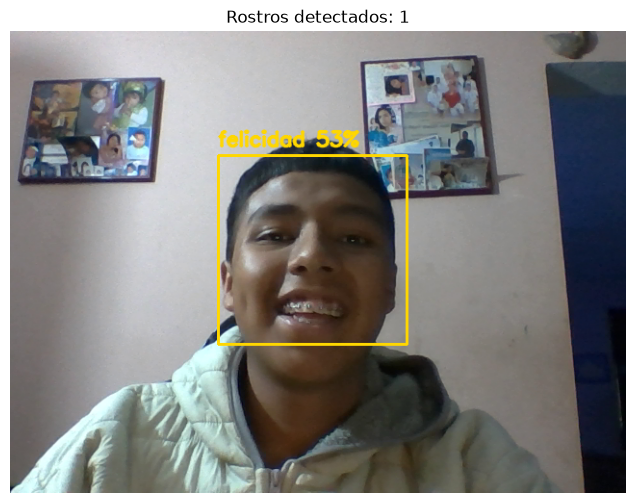

In [40]:
import matplotlib.pyplot as plt

# Etiquetas para mostrar en pantalla (sin tildes) y color de cada emoción en BGR
EMOTION_LABELS_ES = {
    "angry": "enojo", "disgust": "asco", "fear": "miedo", "happy": "felicidad",
    "neutral": "neutral", "sad": "tristeza", "surprise": "sorpresa",
}
EMOTION_COLORS = {
    "angry": (0, 0, 255), "disgust": (0, 128, 0), "fear": (128, 0, 128), "happy": (0, 215, 255),
    "neutral": (200, 200, 200), "sad": (255, 0, 0), "surprise": (0, 140, 255),
}


def draw_results(frame, boxes, probs):
    # Dibuja sobre una copia del cuadro: un rectángulo por rostro y la emoción con su confianza.
    output = frame.copy()
    for (x, y, w, h), face_probs in zip(boxes, probs):
        class_index = int(face_probs.argmax())
        emotion = CLASS_NAMES[class_index]
        color = EMOTION_COLORS[emotion]
        label = f"{EMOTION_LABELS_ES[emotion]} {face_probs[class_index]:.0%}"
        cv2.rectangle(output, (x, y), (x + w, y + h), color, 2)
        cv2.putText(output, label, (x, max(y - 10, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2, cv2.LINE_AA)
    return output


def show_bgr(image, title=""):
    # Matplotlib espera RGB; OpenCV entrega BGR, así que se convierte antes de mostrar.
    plt.figure(figsize=(8, 6))
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


# --- Flujo completo sobre la foto ---
start = time.perf_counter()
boxes = detect_faces(gray)
detection_ms = 1000 * (time.perf_counter() - start)

if boxes:
    faces = np.stack([extract_face(gray, box) for box in boxes])  # (N, 48, 48)
    start = time.perf_counter()
    probs = predict_emotions(faces)                               # (N, 7) con TTA
    prediction_ms = 1000 * (time.perf_counter() - start)
else:
    faces, probs, prediction_ms = np.empty((0, FACE_SIZE, FACE_SIZE)), np.empty((0, 7)), 0.0

print(f"Rostros detectados: {len(boxes)}  {boxes}")
print(f"Tiempo de detección: {detection_ms:.1f} ms | tiempo de predicción: {prediction_ms:.1f} ms")
show_bgr(draw_results(frame, boxes, probs), f"Rostros detectados: {len(boxes)}")

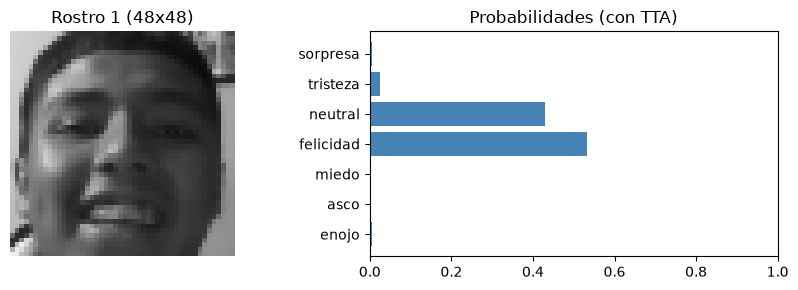

In [41]:
# --- Lo que realmente "ve" el modelo: cada rostro en 48x48 y sus probabilidades ---
if len(faces) == 0:
    print("No se detectó ningún rostro. Prueba con más luz, de frente a la cámara, y vuelve a ejecutar 2.1.")
else:
    fig, axes = plt.subplots(len(faces), 2, figsize=(9, 3 * len(faces)), squeeze=False)
    for i, (face, face_probs) in enumerate(zip(faces, probs)):
        axes[i, 0].imshow(face, cmap="gray", vmin=0, vmax=255)
        axes[i, 0].set_title(f"Rostro {i + 1} (48x48)")
        axes[i, 0].axis("off")
        labels_es = [EMOTION_LABELS_ES[c] for c in CLASS_NAMES]
        axes[i, 1].barh(labels_es, face_probs, color="steelblue")
        axes[i, 1].set_xlim(0, 1)
        axes[i, 1].set_title("Probabilidades (con TTA)")
    plt.tight_layout()
    plt.show()

### 2.3 Experimento con los parámetros del detector

Probamos varias combinaciones sobre la **misma foto** para ver el compromiso entre **sensibilidad, falsos positivos y velocidad**. Con una sola persona frente a la cámara, lo ideal es **1 rostro detectado**: 0 indica que el detector es demasiado estricto y más de 1, falsos positivos.

El tiempo importa porque en tiempo real se detecta en **cada cuadro**: a 30 FPS hay unos 33 ms por cuadro para detectar **y** predecir.

In [42]:
import pandas as pd

experiments = []
for scale_factor in (1.05, 1.1, 1.3):
    for min_neighbors in (1, 3, 5, 8):
        start = time.perf_counter()
        found = detect_faces(gray, scale_factor=scale_factor, min_neighbors=min_neighbors)
        elapsed_ms = 1000 * (time.perf_counter() - start)
        experiments.append({
            "scale_factor": scale_factor,
            "min_neighbors": min_neighbors,
            "faces_detected": len(found),
            "detection_ms": round(elapsed_ms, 1),
        })

haar_results = pd.DataFrame(experiments)
display(haar_results)

# Se guardan solo números (sin imágenes) como evidencia para el reporte
haar_results.to_csv(METRICS_DIR / "haar_parameter_test.csv", index=False)
print("Guardado en reports/metrics/haar_parameter_test.csv")
print(f"Configuración elegida: scaleFactor={SCALE_FACTOR}, minNeighbors={MIN_NEIGHBORS}, minSize={MIN_FACE_SIZE}")

,scale_factor,min_neighbors,faces_detected,detection_ms
0,1.05,1,3,32.1
1,1.05,3,2,32.8
2,1.05,5,1,33.4
3,1.05,8,1,32.4
4,1.10,1,2,18.8
5,1.10,3,1,19.1
6,1.10,5,1,18.5
7,1.10,8,1,17.4
8,1.30,1,2,6.9
9,1.30,3,1,7.1


Guardado en reports/metrics/haar_parameter_test.csv
Configuración elegida: scaleFactor=1.1, minNeighbors=5, minSize=(60, 60)


### Evidencias de la Parte 2 para el reporte
- Captura de la foto con el **rectángulo y la emoción** detectada (puedes taparte o usar la captura solo en el video; no la subas a GitHub).
- Captura del **rostro en 48x48 con sus probabilidades**: muestra qué recibe realmente la CNN.
- Captura de la tabla y el archivo `reports/metrics/haar_parameter_test.csv`, que justifican los parámetros elegidos.
- **Antes del commit:** borra la salida de las celdas de 2.2 que muestran tu cara (clic derecho → *Clear Cell Output*) y guarda el notebook.